# What actually helps, and what 300 conversations can support

Notebook 03 left three things unfinished.

Its confidence intervals came from a normal approximation on accuracy, which is the
wrong tool: EN-300 and KK-300 are *the same 300 conversations*, so the comparison is
paired and deserves a paired test. It reported that the best Kazakh model finds "one
scam in four" without checking whether that was a Kazakh problem at all. And it ended
by recommending translate-train without running it.

All three are here. The last one works, and the second one turns out to have been
asking the wrong question.

Prerequisites:

```
python scripts/analyse_results.py  --features data/features --merged data/merged \
    --out data/experiments
python scripts/translate_train.py  --merged data/merged --features data/features \
    --out data/silver --conversations 4000
python scripts/run_crosslingual.py --features data/features --merged data/merged \
    --out data/experiments --embeddings data/embeddings \
    --silver data/silver/silver_kk.parquet
```

In [1]:
import json
import pathlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT / "scripts"))

import build_features as bf
import run_crosslingual as rx
from analyse_results import bootstrap_f1, mcnemar

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dcdcd8"
CLASSES = ["LEGITIMATE", "SUSPICIOUS", "SCAM"]


def bare_axes(ax, xlabel=None):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    return ax


features, merged = rx.load(ROOT / "data" / "features", ROOT / "data" / "merged")
train, english_300, kazakh = rx.split_sets(features, merged)
truth = english_300.label_3class.to_numpy()
per_conversation = pd.read_csv(ROOT / "data" / "experiments" / "per_conversation.csv")
results = pd.read_csv(ROOT / "data" / "experiments" / "crosslingual_results.csv").set_index("model")
print(f"{len(english_300)} paired conversations, {len(results)} models")

300 paired conversations, 12 models


## 1. The right test for paired data

McNemar looks only at the conversations a model gets right in one language and wrong
in the other, which is exactly the question "does translation cost anything?".
Intervals are a percentile bootstrap over conversations rather than an assumed
distribution.

In [2]:
print((ROOT / "data" / "experiments" / "analysis.md").read_text()
      .split("## Is the English/Kazakh gap real?")[1].split("##")[0].strip())

| Model | EN macro-F1 (95% CI) | KK macro-F1 (95% CI) | right in EN only | right in KK only | McNemar p |
|---|---|---|---:|---:|---:|
| hand features | 0.563 (0.517–0.612) | 0.539 (0.481–0.592) | 44 | 21 | 0.0059 |
| char n-gram | 0.736 (0.685–0.785) | 0.491 (0.434–0.545) | 84 | 11 | 4.5e-15 |


Both gaps are real — but note how different they are. The hand features lose
significantly yet slightly (p = 0.006 on a 0.024 drop), while char n-grams lose a
quarter of their score at p = 4.5 × 10⁻¹⁵.

And the comparison notebook 03 could not resolve stays unresolved: hand features beat
char n-grams on 65 Kazakh conversations, char n-grams beat hand features on 51,
**p = 0.227**. Properly tested, that is a tie — the earlier ±5.6 point hand-wave
happened to reach the right conclusion for the wrong reason.

## 2. Where the loss actually is — and a correction

Notebook 03 presented "SCAM recall 0.24 on Kazakh" as the project's most important
number, implying translation was destroying scam detection.

That reading was wrong, and the breakdown says so plainly.

In [3]:
by_class = per_conversation.groupby("label").agg(
    n=("id", "size"), EN_accuracy=("en_right", "mean"),
    KK_accuracy=("kk_right", "mean"), lost_in_translation=("lost", "sum"))
display(by_class.round(3))

missed = per_conversation[(per_conversation.label == "SCAM") & ~per_conversation.kk_right]
print(f"SCAM conversations missed in Kazakh:        {len(missed)}")
print(f"  ... of which correct in English:          {int(missed.en_right.sum())}")
print(f"  ... missed in BOTH languages:             {int((~missed.en_right).sum())}")
print(f"\nSCAM accuracy in English: {by_class.loc['SCAM', 'EN_accuracy']:.2f}"
      f"  -- lower than in Kazakh ({by_class.loc['SCAM', 'KK_accuracy']:.2f})")

,n,EN_accuracy,KK_accuracy,lost_in_translation
label,,,,
LEGITIMATE,100,0.97,0.78,20
SCAM,100,0.11,0.24,5
SUSPICIOUS,100,0.84,0.67,19


SCAM conversations missed in Kazakh:        76
  ... of which correct in English:          5
  ... missed in BOTH languages:             71

SCAM accuracy in English: 0.11  -- lower than in Kazakh (0.24)


**SCAM detection was never a translation problem.** Accuracy on SCAM is 0.11 in
English and 0.24 in Kazakh — the model is *worse* on its native language. Of 76 missed
Kazakh scams only 5 are classified correctly in English; the other 71 are beyond the
model in either language.

What translation actually costs is the two classes the model was good at: LEGITIMATE
drops 0.97 → 0.78 and SUSPICIOUS 0.84 → 0.67. 44 of 300 conversations are lost that
way.

In [4]:
print((ROOT / "data" / "experiments" / "analysis.md").read_text()
      .split("### By style variant")[1].split("###")[0].strip())

| style variant | n | EN acc | KK acc | lost |
|---|---:|---:|---:|---:|
| support_formal | 46 | 0.61 | 0.52 | 8 |
| slightly_slangy | 44 | 0.50 | 0.36 | 7 |
| internet | 37 | 0.76 | 0.62 | 7 |
| plain | 36 | 0.83 | 0.67 | 7 |
| discord_casual | 35 | 0.60 | 0.66 | 2 |
| short_professional | 30 | 0.77 | 0.73 | 2 |
| operator_brief | 29 | 0.62 | 0.48 | 6 |
| broken_english | 24 | 0.58 | 0.54 | 3 |
| leetspeak | 19 | 0.42 | 0.53 | 2 |


Two details worth keeping:

- **Leetspeak scores better in Kazakh than in English** (0.42 → 0.53). Rendering
  `H3ll0` as readable Kazakh removes the obfuscation, so the Kazakh row is an easier
  problem than its source. That is a direct consequence of a translation decision made
  long before any model existed.
- **The translation cost rises with length** — 10 conversations lost in the shortest
  quartile against 16 in the longest.

## 3. Which boundary is hard

If SCAM is missed in both languages, the question is not about Kazakh at all. It is
whether the label is learnable from text.

SCAM and SUSPICIOUS both carry `should_trigger_scam_defense = True`. The only thing
separating them is `decision_class`: refuse / escalate / block on one side,
request_verification / audit on the other. That is a judgement about what a correct
agent should **do** — and the conversation never says it.

In [5]:
english = merged[merged.language == "en"]
attack = english[english.label_3class.isin(["SCAM", "SUSPICIOUS"])]
display(pd.crosstab(attack.decision_class, attack.label_3class))
print("Perfectly separable by decision_class -- which is how the label was built.")
print("The question is whether anything in the *text* separates them too.")

label_3class,SCAM,SUSPICIOUS
decision_class,,
allow_safe_action,0,8
audit,0,1412
block_actor,38,0
deny_privileged_action,30,0
escalate,773,0
ignore,73,0
refuse,4387,1
request_verification,0,4219
share_safe_info,0,4


Perfectly separable by decision_class -- which is how the label was built.
The question is whether anything in the *text* separates them too.


In [6]:
print((ROOT / "data" / "experiments" / "analysis.md").read_text()
      .split("## Which boundary is hard?")[1].split("Chance on the last row")[0]
      .split("| Task |")[1].strip())

EN | KK |
|---|---:|---:|
| 3-class, as defined | 0.563 | 0.539 |
| attack vs not (SCAM and SUSPICIOUS merged) | **0.879** | **0.764** |
| SCAM vs SUSPICIOUS alone | 0.537 | 0.578 |


**Chance on the last row is 0.500.**

The text supports attack detection well — 0.879 in English, 0.764 in Kazakh — and
barely supports the SCAM/SUSPICIOUS split at all. The three-class score of 0.563 is
dominated by a boundary a text-only model has almost no evidence for.

This is a limitation of how the label was defined, not of the features, and it was
found by measurement rather than argued for. It does **not** invalidate the three-class
label: it still refines the binary flag without contradicting it, and every SUSPICIOUS
row carries named risk indicators. What it means is that **any three-class number
should be reported next to the binary one**, because 0.563 understates how well the
text is actually understood.

## 4. Translate-train: the thing that works

The encoders in notebook 03 tried to bridge the two languages *representationally* and
failed. The alternative is blunt: give the model Kazakh to train on.

`scripts/translate_train.py` machine-translates 4,000 English training conversations
with NLLB-200. Two things make it cheap and keep it honest:

- **distinct strings, not message slots** — 4,000 conversations hold 16,687 distinct
  strings, so most of the work is repeats. The same observation that drove the
  translation memory;
- **entity masking** — every URL, amount, code and phone number is replaced by a
  placeholder before translation and restored after, using the patterns
  `validate_translation.py` already checks. Without it `$199` becomes `199 доллар`.

This is silver data. The 300 human translations stay the only gold Kazakh, and are
never trained on.

In [7]:
silver = pd.read_parquet(ROOT / "data" / "silver" / "silver_kk.parquet")
print(f"{len(silver):,} machine-translated conversations, "
      f"{dict(silver.label_3class.value_counts())}")

shown = results.loc[[i for i in results.index if "silver" in i or i in (
    "char n-gram TF-IDF (3-5)", "word TF-IDF (1-2)", "hand features (all 54)")]]
shown.round(3)

3,999 machine-translated conversations, {'LEGITIMATE': np.int64(1333), 'SUSPICIOUS': np.int64(1333), 'SCAM': np.int64(1333)}


,EN-300,KK-300,gap
model,,,
hand features (all 54),0.563,0.539,0.024
char n-gram TF-IDF (3-5),0.736,0.491,0.245
word TF-IDF (1-2),0.690,0.416,0.274
hand features + silver KK,0.528,0.564,-0.037
char n-gram TF-IDF + silver KK,0.736,0.687,0.050
word TF-IDF + silver KK,0.690,0.661,0.029


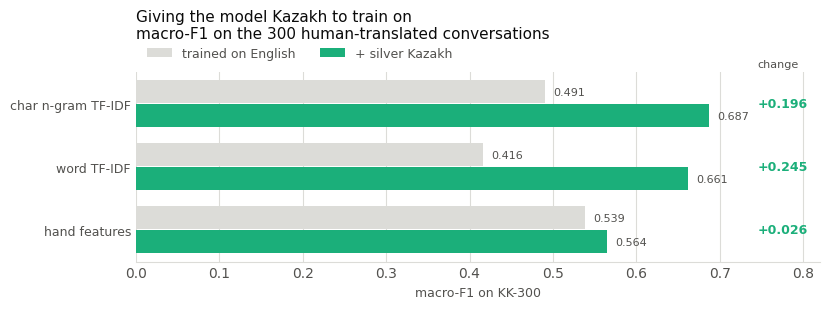

In [8]:
pairs = [("char n-gram TF-IDF (3-5)", "char n-gram TF-IDF + silver KK"),
         ("word TF-IDF (1-2)", "word TF-IDF + silver KK"),
         ("hand features (all 54)", "hand features + silver KK")]
labels = [a.split(" (")[0] for a, _ in pairs][::-1]
before = [results.loc[a, "KK-300"] for a, _ in pairs][::-1]
after = [results.loc[b, "KK-300"] for _, b in pairs][::-1]

y = np.arange(len(labels))
height = 0.36
fig, ax = plt.subplots(figsize=(8.4, 3.2))
ax.barh(y + height / 2 + 0.01, before, height=height, color=GRID, label="trained on English")
ax.barh(y - height / 2 - 0.01, after, height=height, color=AQUA, label="+ silver Kazakh")
for i, (b, a) in enumerate(zip(before, after)):
    ax.text(b + 0.01, i + height / 2 + 0.01, f"{b:.3f}", va="center", fontsize=8, color=MUTED)
    ax.text(a + 0.01, i - height / 2 - 0.01, f"{a:.3f}", va="center", fontsize=8, color=MUTED)
    ax.text(0.745, i, f"+{a - b:.3f}" if a > b else f"{a - b:.3f}", va="center",
            fontsize=9, color=AQUA, fontweight="600")

ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
ax.set_title("Giving the model Kazakh to train on\nmacro-F1 on the 300 human-translated conversations",
             loc="left", color=INK, fontsize=11, pad=24)
bare_axes(ax, "macro-F1 on KK-300")
ax.set_xlim(0, 0.82)
ax.text(0.745, len(labels) - 0.42, "change", fontsize=8, color=MUTED)
ax.legend(frameon=False, ncol=2, labelcolor=MUTED, fontsize=9,
          loc="lower left", bbox_to_anchor=(0, 1.005))
plt.tight_layout(); plt.show()

In [9]:
# is the jump real? paired again, on the model that moved most
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

text = merged.set_index("id").text
silver["text"] = silver.messages.apply(
    lambda m: "\n".join(x.get("content") or "" for x in json.loads(m)))


def char_model(texts, labels):
    return make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                        max_features=200_000, sublinear_tf=True),
        LinearSVC(C=1.0, random_state=0)).fit(texts, labels)


english_only = char_model(text.loc[train.id].tolist(), train.label_3class)
with_silver = char_model(text.loc[train.id].tolist() + silver.text.tolist(),
                         pd.concat([train.label_3class, silver.label_3class],
                                   ignore_index=True))

kk_text = text.loc[kazakh.id].tolist()
before_pred, after_pred = english_only.predict(kk_text), with_silver.predict(kk_text)
rng = np.random.default_rng(0)
lo_b, hi_b = bootstrap_f1(truth, before_pred, rng)
lo_a, hi_a = bootstrap_f1(truth, after_pred, rng)
fixed, broken, p = mcnemar(after_pred == truth, before_pred == truth)

print(f"English only     {f1_score(truth, before_pred, average='macro'):.3f}  "
      f"[{lo_b:.3f}, {hi_b:.3f}]")
print(f"+ silver Kazakh  {f1_score(truth, after_pred, average='macro'):.3f}  "
      f"[{lo_a:.3f}, {hi_a:.3f}]")
print(f"\nconversations fixed by silver: {fixed},  broken: {broken},  "
      f"McNemar p = {p:.3g}")
print("\nper class, with silver:")
print(classification_report(truth, after_pred, zero_division=0))

English only     0.491  [0.430, 0.547]
+ silver Kazakh  0.687  [0.636, 0.736]

conversations fixed by silver: 76,  broken: 21,  McNemar p = 1.72e-08

per class, with silver:
              precision    recall  f1-score   support

  LEGITIMATE       0.73      0.90      0.81       100
        SCAM       0.71      0.45      0.55       100
  SUSPICIOUS       0.66      0.75      0.70       100

    accuracy                           0.70       300
   macro avg       0.70      0.70      0.69       300
weighted avg       0.70      0.70      0.69       300



**It works, and it is not close.** Char n-grams on Kazakh go from 0.491 to **0.687** —
76 conversations fixed against 21 broken, p ≈ 1.7 × 10⁻⁸, with non-overlapping
bootstrap intervals. English is unchanged at 0.736, so the Kazakh data costs nothing on
the source language. The cross-lingual gap collapses from 0.245 to 0.050.

SCAM recall, the number that started section 2, goes from 0.24 to **0.45** — still the
weakest class, for the reason section 3 gives, but nearly doubled.

The contrast with notebook 03 is the point worth presenting. Two multilingual encoders
tried to bridge the languages in representation space and neither beat 54 hand-built
numbers. Machine-translating the training data — cruder, cheaper, and done on a laptop
in 79 minutes — beat everything.

## 5. How good is the silver data?

Most projects asserting "we machine-translated the training set" cannot check. This one
has 300 human translations of the same English, so the machine can be graded.

In [10]:
report = ROOT / "data" / "experiments" / "mt_quality.md"
print(report.read_text() if report.exists()
      else "not generated yet -- run scripts/score_mt_quality.py")

# How good is the machine translation?

The 300 human translations are the reference. The same English was run
through NLLB-200-distilled-600M with the entity masking used for the
silver training data.

Conversations compared: 300

| Measure | Value |
|---|---:|
| chrF against the human translation | 0.549 |
| LaBSE cosine against the human translation | 0.857 |
| conversations with every entity preserved | 259 / 300 |
| entities dropped in total | 99 |

chrF runs 0 to 1. Machine translation is not expected to reproduce a
human translation word for word, so a middling score is normal and the
number is here to be reported honestly, not to be passed.



**chrF 0.549 is the number that matters, and it is good news in a way that needs
explaining.** chrF runs 0 to 1 and measures character n-gram overlap with the human
translation. 0.549 means the machine and the human produce *noticeably different*
Kazakh — same meaning, different wording, as you would expect.

That rules out the obvious objection to section 4. If the silver data had been nearly
identical to the gold, the +0.196 could have been the model memorising NLLB's
particular idiolect and then being tested on it. It is not: the model trains on one
dialect of Kazakh and is evaluated on a visibly different one, and still gains 20
points. The gain is Kazakh, not NLLB.

Entity masking held up too — 259 of 300 conversations keep every URL, amount and code
through machine translation, against 300 of 300 for the human translations. The 99
dropped entities are the price of silver data, and they are counted rather than
assumed.

## 6. How much silver is enough?

Translating more looked like the obvious next step. It is cheap to check first, using
the data already produced: train on 0, 250, 500 … of the silver conversations and watch
the score on the gold Kazakh.

,silver,kk_f1,lo,hi
0,0,0.491,0.430,0.545
1,250,0.566,0.509,0.622
2,500,0.622,0.569,0.669
3,1000,0.680,0.626,0.737
4,2000,0.687,0.638,0.739
5,3000,0.686,0.636,0.738
6,3999,0.687,0.635,0.737


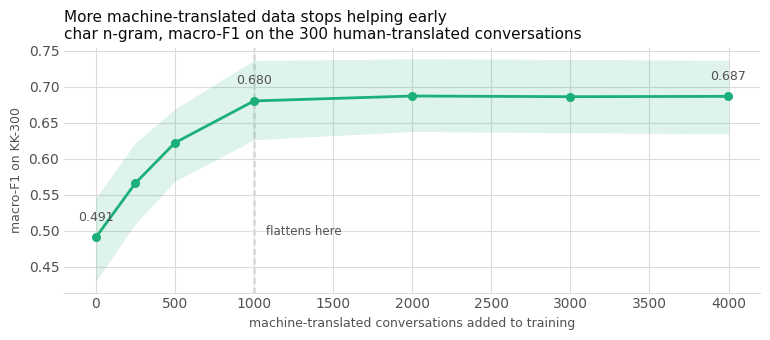

In [11]:
curve = pd.read_csv(ROOT / "data" / "experiments" / "silver_curve.csv")
display(curve.round(3))

fig, ax = plt.subplots(figsize=(7.8, 3.5))
ax.fill_between(curve.silver, curve.lo, curve.hi, color=AQUA, alpha=0.15, linewidth=0)
ax.plot(curve.silver, curve.kk_f1, color=AQUA, linewidth=2, marker="o", markersize=5.5)
for row in curve.itertuples():
    if row.silver in (0, 1000, int(curve.silver.iloc[-1])):
        ax.annotate(f"{row.kk_f1:.3f}", (row.silver, row.kk_f1),
                    textcoords="offset points", xytext=(0, 12), ha="center",
                    fontsize=9, color=MUTED)
ax.axvline(1000, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=0)
ax.annotate("flattens here", (1000, curve.kk_f1.min()), textcoords="offset points",
            xytext=(9, 2), fontsize=8.5, color=MUTED)
ax.set_title("More machine-translated data stops helping early\nchar n-gram, macro-F1 on the 300 human-translated conversations",
             loc="left", color=INK, fontsize=11)
bare_axes(ax, "machine-translated conversations added to training")
ax.set_ylabel("macro-F1 on KK-300", color=MUTED, fontsize=9)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
plt.tight_layout(); plt.show()

**It flattens at about 1,000 conversations.** Going from 1,000 to 3,999 buys +0.007,
well inside the interval.

So the 4,000 we translated was roughly four times more than the job needed, and
translating the remaining 8,000 of the training pool would gain nothing. The run took
79 minutes; the useful part of it took about twenty.

This is the cheapest experiment in the notebook and it cancelled the most expensive
plan — worth running before buying compute rather than after.

## 7. Where this leaves the project

**Revised ordering**, by what the evidence now supports rather than by expectation:

1. **Report the binary task alongside the three-class one.** 0.879 / 0.764 is the
   honest description of what the text supports; 0.563 is dominated by a boundary that
   is not in the text. Costs nothing, and it is the single largest improvement to how
   this work reads.
2. **More *human* Kazakh** — 326 per class available. Every number here is measured on
   the gold 300, where the bootstrap interval is still ±5 points, so this is what buys
   resolution between models.
3. **Fine-tune rather than freeze.** The only untested idea left, now with a real bar
   to clear at 0.687. This is the one remaining step that genuinely needs a GPU.

**Not** more silver data — section 6 cancelled that, and it was the obvious next move
until it was measured.

**What has not moved:** no native speaker has reviewed the Kazakh. Every number in this
notebook rests on 300 translations whose fluency is unverified.